In [25]:
import pandas as pd
import numpy as np
import yfinance as yf

from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import matplotlib.pyplot as plt

import warnings
from statsmodels.tools.sm_exceptions import InterpolationWarning
warnings.simplefilter('ignore', InterpolationWarning)

In [26]:
df = pd.read_csv('Data/Sector_ETF_OVTLYR_data.csv')
df = df.rename(columns={'Quotedate':'Date','StockSymbol':'Ticker',' ClosePrice ':'Close','Bull Per FullStock (Normal)':'Bull_per_norm','Bull Per FullStock (Active)':'Bull_per_act'})
df['Date'] = pd.to_datetime(df['Date'])
df = df.drop(columns=['Communication.Services FG Value',
       'Consumer.Discretionary FG Value', 'Consumer.Staples FG Value',
       'Energy FG Value', 'Financials FG Value', 'Health.Care FG Value',
       'Industrials FG Value', 'Information.Technology FG Value',
       'Materials FG Value', 'Real.Estate FG Value', 'Utilities FG Value'])
df['Signal'] = df['Signal'].fillna(0)
df['Close'] = df['Close'].str.replace('$', '')
df['Close'] = pd.to_numeric(df['Close'])
all_tickers = df['Ticker'].unique()
df = df.sort_values(by=['Date','Ticker'])

df['Heatmap'] = df.groupby('Ticker')['Heatmap'].transform(lambda x: x.shift(1))
df['FG_Value'] = df.groupby('Ticker')['FG_Value'].transform(lambda x: x.shift(1))


C:\Users\scott\AppData\Local\Temp\ipykernel_34268\3395480269.py:9: Pandas4Warning: 'int' is not supported as a fill value for str dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  df['Signal'] = df['Signal'].fillna(0)


In [27]:
def generate_slope_Z_score_rms(df,name,slope_len = 10, rms_lookback = 60):
       df[f'{name}_Slope{slope_len}'] = df.groupby('Ticker')[name].transform(lambda x: x.diff(slope_len))
       df[f'{name}_Slope{slope_len}_rms'] = df.groupby('Ticker')[f'{name}_Slope10'].transform(lambda x: np.sqrt((x**2).rolling(rms_lookback).mean()))


generate_slope_Z_score_rms(df=df,name='Heatmap')

In [28]:
def check_stationarity(name):
    rows = []
    for tik in all_tickers:
        df0 = df[df['Ticker'] == tik][name].dropna()
        rows.append({
            'Ticker': tik,
            'ADF p-value': adfuller(df0, result_object=False)[1],
            'KPSS p-value': kpss(df0, result_object=False)[1],
        })

    stationarity_df = pd.DataFrame(rows).set_index('Ticker')
    stationarity_df['Stationary (1%)'] = (stationarity_df['ADF p-value'] < 0.01) & (stationarity_df['KPSS p-value'] > 0.01)
    return stationarity_df

check_stationarity('Heatmap_Slope10')
# check_stationarity('Heatmap_Slope10_rms')

,ADF p-value,KPSS p-value,Stationary (1%)
Ticker,,,
XLE,2.912428e-14,0.1,True
XLF,2.726559e-17,0.1,True
XLI,3.228766e-16,0.1,True
XLK,1.915918e-17,0.1,True
XLP,1.414021e-24,0.1,True
XLU,2.871401e-21,0.1,True
XLV,3.690892e-21,0.1,True
XLY,5.583389e-18,0.1,True
XLB,2.026785e-17,0.1,True


In [29]:
tickers = all_tickers.tolist()
raw = yf.download(tickers,
                  start=df['Date'].min() - pd.Timedelta(days=120),   # ATR warm-up
                  end=df['Date'].max() + pd.Timedelta(days=1),
                  auto_adjust=False, progress=False, interval='1d')

def atr_wilder(d, n=14):
    pc = d['Close'].shift(1)
    tr = pd.concat([d['High'] - d['Low'],(d['High'] - pc).abs(),(d['Low'] - pc).abs()], axis=1).max(axis=1)
    return tr.ewm(alpha=1/n, adjust=False, min_periods=n).mean()

frames = []
for t in tickers:
    d = raw.xs(t, axis=1, level=1)[['High', 'Low', 'Close','Open']].dropna().copy()
    d['ATR14'] = atr_wilder(d)
    d['ATR14_pct'] = d['ATR14'] / d['Close']
    d = d.rename(columns={'Close': 'YF_Close'})
    d['Ticker'] = t
    frames.append(d.reset_index())          # index is named 'Date'

ohlc = pd.concat(frames, ignore_index=True)
df = df.merge(ohlc, on=['Date', 'Ticker'], how='left')

df['Close'] = df['YF_Close'] #use yfinance instead of ovtlyr close data
df['Price'] = df.groupby('Ticker')['Open'].transform(lambda x: x.shift(-1))

# display(df.groupby('Ticker')['ATR14'].apply(lambda s: s.isna().sum()))

c:\Users\scott\Desktop\Ovtlyr Work\Stage2_HM_spike\HM_spike\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\scott\Desktop\Ovtlyr Work\Stage2_HM_spike\HM_spike\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
c:\Users\scott\Desktop\Ovtlyr Work\Stage2_HM_spike\HM_spike\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1

In [30]:
def add_stage(df, w_ma, w_slope, eps=0.0):
    ma = df.groupby('Ticker')['Close'].transform(lambda x: x.rolling(w_ma).mean())
    slope = ma.groupby(df['Ticker']).pct_change(w_slope, fill_method=None)
    dist = df['Close'] / ma - 1
    ok = dist.notna() & slope.notna()

    above, rising, falling = dist > 0, slope > eps, slope < -eps
    stage = pd.Series(np.select([above & rising, ~above & falling, above], [2, 4, 3], default=1),
                      index=df.index).where(ok)

    df[f'Dist_MA'] = dist
    df[f'MA_slope'] = slope
    df[f'Stage'] = stage
    df[f'Stage2'] = (stage == 2).astype(float).where(ok)
    df[f'Stage2_Heatmap_Slope'] = ((stage == 2) & ((df['Heatmap_Slope10'] > df['Heatmap_Slope10_rms']))).astype(float).where(ok & df['Heatmap_Slope10_rms'].notna())

add_stage(df, w_ma=50, w_slope=10)
    

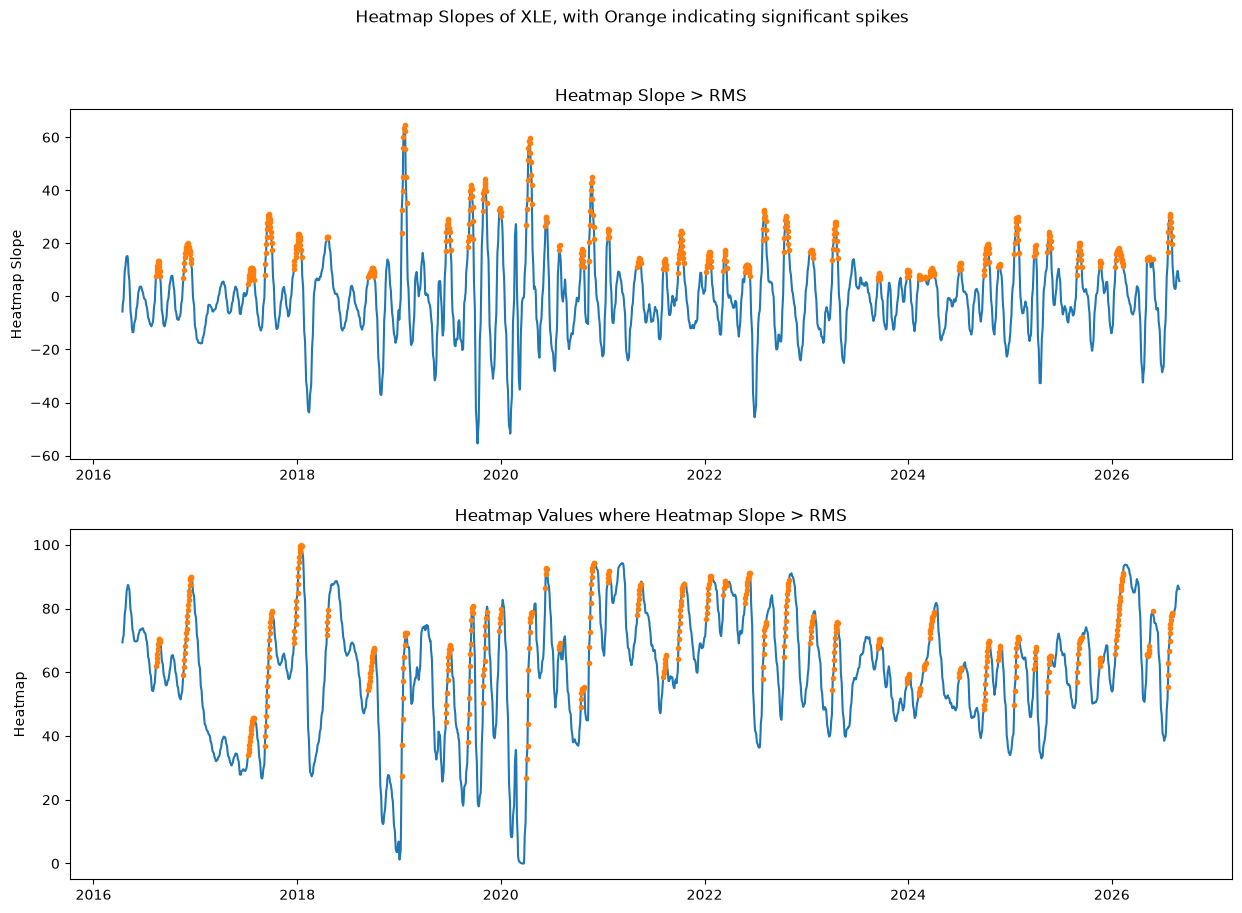

In [31]:
tik = 'XLE'
df0 = df[df['Ticker'] == tik][['Date','Heatmap','Heatmap_Slope10','Heatmap_Slope10_rms']].dropna()

def heatmap_spike_plotter(df,base_plot_ylab,title):
    df = df.dropna()
    fig, (ax1,ax2) = plt.subplots(2,1,figsize = (15,10))
    ax1.plot(df['Date'],df['Heatmap_Slope10'])
    ax1.plot(df[df['Heatmap_Slope10'] > df['Heatmap_Slope10_rms']]['Date'],df[df['Heatmap_Slope10'] > df['Heatmap_Slope10_rms']]['Heatmap_Slope10'],'.')
    ax1.set_title('Heatmap Slope > RMS')
    ax1.set_ylabel(base_plot_ylab)

    ax2.plot(df['Date'],df['Heatmap'])
    ax2.plot(df[df['Heatmap_Slope10'] > df['Heatmap_Slope10_rms']]['Date'],df[df['Heatmap_Slope10'] > df['Heatmap_Slope10_rms']]['Heatmap'],'.')
    ax2.set_title('Heatmap Values where Heatmap Slope > RMS')
    ax2.set_ylabel('Heatmap')

    fig.suptitle(title)

heatmap_spike_plotter(df=df0,base_plot_ylab = 'Heatmap Slope',title=f"Heatmap Slopes of {tik}, with Orange indicating significant spikes")


In [32]:
df0 = df.sort_values(['Ticker','Date']).dropna()
SPLIT = '2024-01-01'
train,test = df0[df0['Date'] <= pd.to_datetime(SPLIT)],df0[df0['Date'] > pd.to_datetime(SPLIT)]
all_df = df0

train.to_csv('Transformed_Sector_data_train.csv')
test.to_csv('Transformed_Sector_data_test.csv')
all_df.to_csv('Transformed_Sector_data_all.csv')